# BME688 smell classifier: clean air / spicy / bad smell

This notebook builds the first smell classifier from the recordings in `masuratori`.
Each section matches one step of the plan:

1. **Settings**: classes, boards, profiles
2. **Read the data**: one table of heater cycles
3. **Clean-air reference**: remove the offset between boards
4. **Features**: one example = 2 minutes = the curve shape for each heater profile
5. **Train and test**: logistic regression and gradient boosting, tested honestly
6. **Test on board 3**, which never took part in training
7. **Export** the model as JSON for the interface

Folder layout expected (same as on the Mac):
```
masuratori/bme1/<object>/<YYYY-MM-DD_HH-MM-SS_NNmin>/sensorN_<profile>.csv
masuratori/bme2/...   masuratori/bme4/...
masuratori/teste_simultane/Test_2_aer_curat/bme1/Aer_curat/<run>/...   (unzip teste_simultane.zip first)
```

In [12]:
import json, os, re, unicodedata
from datetime import datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, confusion_matrix
try:                                   # lightgbm if installed, otherwise scikit-learn
    from lightgbm import LGBMClassifier
    def make_boosting():
        return LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=7, max_depth=3,
                              min_child_samples=20, subsample=0.8, subsample_freq=1,
                              colsample_bytree=0.8, reg_lambda=1.0, class_weight='balanced', verbose=-1)
    BOOSTING_NAME = 'LightGBM'
except ImportError:
    from sklearn.ensemble import HistGradientBoostingClassifier
    def make_boosting():
        return HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200,
                                              min_samples_leaf=20, l2_regularization=1.0,
                                              class_weight='balanced', random_state=0)
    BOOSTING_NAME = 'Gradient boosting (scikit-learn)'

## 1. Settings
Change these to try other classes. `SPICY` and `BAD_SMELL` come from the categories in
*09. Experimente realizate*, with two fixes: `Creion_nazal_mentolat` is minty, so it moves to spicy;
`Chibrituri_arse` (burnt) and `Haine_la_uscat` (laundry) are not bad smells, so they are left out.

In [13]:
ROOT = Path(os.environ.get('BME_ROOT', 'masuratori'))   # folder with bme1, bme2, bme4 and teste_simultane
TRAIN_BOARDS = ['bme1', 'bme2', 'bme4']      # boards used for training
TEST_BOARD = 'bme3'                          # board kept only for testing
CLASSES = ['clean_air', 'spicy', 'bad_smell']

SPICY = {
    'bme1': ['Boia_dulce_Kotanyi', 'Ceai_de_fructe_de_padure', 'Ceai_de_menta', 'Chili', 'Chimen', 'Cimbrisor',
             'Cuisoare', 'Foi_de_dafin', 'Ienibahar', 'Matcha_Vifon', 'Nucsoara', 'Pasta_de_dinti_Colgate',
             'Piper_Negru_boabe', 'Sirop_Calmotusin'],
    'bme2': ['Anason_Stelat', 'Cardamom', 'Ceai_de_sunătoare', 'Ceai_verde_Fares', 'Coriandru', 'Curcuma', 'Curry',
             'Garam_Masala', 'Oregano', 'Pasta_de_dinti_Lacalut', 'Scortisoara'],
    'bme4': ['Amestec_Mediteranean', 'Busuioc_gradina', 'Ceai_rece', 'Halls_Lime_Fresh', 'Creion_nazal_mentolat'],
}
BAD_SMELL = {
    'bme1': ['Adidas_transpirat', 'Cosul_de_gunoi_din_casa', 'Cosul_din_baie', 'Prosop_murdar',
             'Sosete_Transpirate', 'Vant_de_prune_si_varza'],
    'bme2': ['Branza_telemea_puturoasa', 'Sosete_mirositoare'],
    'bme4': ['Burete_bucatarie_uzat', 'Ulei_industrial', 'WC_usa_inchisa_ventilator_off'],
}
CLEAN_AIR_FOLDERS = ['Test']                                      # long clean-air runs
CLEAN_AIR_TESTS = ['Test_2_aer_curat', 'Test_4_Aer_curat_LDO_3V3']  # all boards at the same time

SKIP_MIN = 15          # warm-up, use the second measurement
USE_MAX_MIN = 60       # at most 60 min from the second measurement
USE_MIN = 15           # for files shorter than 15 min
WINDOW_S = 120         # one example = 2 minutes
CLIP_OHM = 1.02e8      # sensor maximum, carries no information
PROFILES = ['hp_301_basic', 'hp_354_standard', 'hp_411_levels', 'hp_501_sweep']
SHARED = ['hp_354_standard', 'hp_411_levels', 'hp_501_sweep']     # profiles board 3 also runs
# 100 C steps often stay at the maximum, so they are skipped
USE_STEPS = {'hp_301_basic': [2, 3, 4, 5, 6, 7, 8, 9], 'hp_354_standard': [0, 4, 5, 6, 7, 8, 9],
             'hp_411_levels': [1, 2, 3, 4, 5, 6, 7, 8, 9], 'hp_501_sweep': [0, 1, 2, 3, 4, 5, 6, 7, 9]}
UNKNOWN_BELOW = 0.6    # below this the answer is unknown

def nfc(s):            # macos can store 'ă' differently
    return unicodedata.normalize('NFC', s)

## 2. Read the data
Every CSV row is one heater step. Ten consecutive steps (gas index 0 to 9) make one **cycle**.
We keep, for every cycle, the time and the logarithm of the resistance at each step.

A *session* is a run of consecutive files of the same object on the same board.
Following the professor's advice, we skip the warm-up (the first measurement) and start with the **second measurement**:
from the second file on (up to 60 minutes) when files are 15 minutes or longer, otherwise minutes 15 to 30.
Using everything after the warm-up instead of only the second file was 1-2 points better in every test.

In [14]:
RUN_RE = re.compile(r'(\d{4}-\d{2}-\d{2}_\d{2}-\d{2}-\d{2})_(\d+)min')

def read_cycles(csv_path):
    # one row per complete heater cycle, nan if clipped
    raw = csv_path.read_bytes().replace(b'\x00', b'').decode('latin1').splitlines()
    rows = []
    for line in raw[1:]:
        p = line.split(',')
        if len(p) == 8:
            try: rows.append((int(p[0]), int(p[2]), float(p[4])))
            except ValueError: pass
    cycles, current, t0 = [], {}, None
    for t, step, ohm in rows:
        if step == 0:
            if len(current) == 10: cycles.append([t0] + [current[i] for i in range(10)])
            current, t0 = {}, t
        current[step] = np.log(ohm) if ohm < CLIP_OHM else np.nan
    if len(current) == 10: cycles.append([t0] + [current[i] for i in range(10)])
    return pd.DataFrame(cycles, columns=['t_ms'] + [f's{i}' for i in range(10)])

def find_sessions(board, label_dir, cls, source):
    # group runs into sessions and skip the warm-up
    runs = []
    for run in label_dir.iterdir():
        m = RUN_RE.match(run.name)
        if run.is_dir() and m:
            runs.append((datetime.strptime(m.group(1), '%Y-%m-%d_%H-%M-%S'), int(m.group(2)), run))
    runs.sort()
    sessions, current = [], []
    for run in runs:
        if current and (run[0] - current[-1][0]).total_seconds() > current[-1][1] * 60 + 120:
            sessions.append(current); current = []
        current.append(run)
    if current: sessions.append(current)
    out = []
    for s in sessions:
        start, dur = s[0][0], s[0][1]
        if source == 'Test_1':                    # recorded back to back with a warm sensor
            use_from = start + pd.Timedelta(minutes=2)   # skip only the first 2 minutes
            use_to = s[-1][0] + pd.Timedelta(minutes=s[-1][1]); files = [r[2] for r in s]
        elif dur >= SKIP_MIN:                       # long files, second file on
            if len(s) < 2: continue
            use_from = s[1][0]
            use_to = min(s[-1][0] + pd.Timedelta(minutes=s[-1][1]), use_from + pd.Timedelta(minutes=USE_MAX_MIN))
            files = [r[2] for r in s[1:] if r[0] < use_to]
        else:                                     # short files, minutes 15-30
            use_from = start + pd.Timedelta(minutes=SKIP_MIN)
            use_to = use_from + pd.Timedelta(minutes=USE_MIN)
            files = [r[2] for r in s if r[0] + pd.Timedelta(minutes=r[1]) > use_from and r[0] < use_to]
        if files:
            out.append(dict(board=board, label=nfc(label_dir.name), cls=cls, source=source,
                            start=start, use_from=use_from, use_to=use_to, files=files))
    return out

sessions = []
for board in TRAIN_BOARDS:
    for label_dir in sorted((ROOT / board).iterdir()):
        name = nfc(label_dir.name)
        cls = ('spicy' if name in map(nfc, SPICY.get(board, [])) else
               'bad_smell' if name in map(nfc, BAD_SMELL.get(board, [])) else
               'clean_air' if name in CLEAN_AIR_FOLDERS else None)
        if cls and label_dir.is_dir():
            sessions += find_sessions(board, label_dir, cls, 'objects')
for test in CLEAN_AIR_TESTS:
    for board_dir in sorted(d for d in (ROOT / 'teste_simultane' / test).iterdir() if d.is_dir()):
        for label_dir in board_dir.iterdir():
            if label_dir.is_dir():
                sessions += find_sessions(board_dir.name, label_dir, 'clean_air', test)
# cinnamon distances, only for testing
for board_dir in sorted(d for d in (ROOT / 'teste_simultane' / 'Test_1_distanta_si_timp_achizitie').iterdir() if d.is_dir()):
    for label_dir in sorted(d for d in board_dir.iterdir() if d.is_dir()):
        for s in find_sessions(board_dir.name, label_dir, 'spicy', 'Test_1'):
            sessions.append(s)

def load_session(s):
    # cycles in the selected range, per sensor and profile
    per_sensor = {}
    lo = s['use_from'].timestamp() * 1000; hi = s['use_to'].timestamp() * 1000
    for f in s['files']:
        for csv in f.glob('sensor*.csv'):
            m = re.match(r'sensor(\d)_(hp_\d+_\w+)\.csv', csv.name)
            if not m: continue
            c = read_cycles(csv)
            per_sensor.setdefault((int(m.group(1)), m.group(2)), []).append(c)
    out = {}
    for key, parts in per_sensor.items():
        c = pd.concat(parts, ignore_index=True).sort_values('t_ms', ignore_index=True)
        # file names and timestamps are both local time
        t0 = c['t_ms'].min()
        offset = (s['use_from'] - datetime.strptime(RUN_RE.match(s['files'][0].name).group(1), '%Y-%m-%d_%H-%M-%S')).total_seconds() * 1000
        length = (s['use_to'] - s['use_from']).total_seconds() * 1000
        rel = c['t_ms'] - t0
        out[key] = c[(rel >= offset) & (rel < offset + length)].assign(rel_s=(rel - offset) / 1000)
    return out

for s in sessions:
    s['data'] = load_session(s)
sessions = [s for s in sessions if s['data'] and min(len(v) for v in s['data'].values()) >= 3]
summary = pd.DataFrame([(s['board'], s['cls'], s['source']) for s in sessions], columns=['board', 'class', 'source'])
print(f'{len(sessions)} usable sessions')
print(summary.groupby(['class', 'board']).size().unstack(fill_value=0))

75 usable sessions
board      bme1  bme2  bme3  bme4
class                            
bad_smell     6     2     0     3
clean_air     7     5     2     2
spicy        20    17     6     5


## 3. Clean-air reference
Every board, sensor and heater step gets its own clean-air value **ln R₀** (the median over a clean-air session).
Each reading then becomes a **response**: `response = ln R₀ − ln R = ln(R₀/R)`.
0 means "like clean air"; positive means the resistance dropped because something is in the air.
A board that reads k times higher has k in both R₀ and R, so the offset cancels.

Each board is **calibrated once**, the same way it will be done on the device: with the clean-air recordings
made on all boards at the same time (Test_2 and Test_4, 22.09) and, for bme4, with its own clean-air Test run.
We tried using the clean-air session closest in time instead; it was worse (50% vs 74% on an unseen board),
because the old clean-air runs were recorded while the sensors were still new and drifting.
A calibration session is never compared with itself: it uses the board's other calibration session.

In [15]:
def median_profile(data):
    return {key: c[[f's{i}' for i in range(10)]].median().to_numpy() for key, c in data.items()}

air_refs = [(s['board'], s['use_from'], id(s), median_profile(s['data']))
            for s in sessions if s['cls'] == 'clean_air' and s['source'] != 'Test_1']
calibrations = [r for r, s in zip(air_refs, [s for s in sessions if s['cls'] == 'clean_air' and s['source'] != 'Test_1'])
                if s['source'] in CLEAN_AIR_TESTS or not any(x['source'] in CLEAN_AIR_TESTS and x['board'] == s['board'] for x in sessions)]

def reference_for(s):
    options = [r for r in calibrations if r[0] == s['board'] and r[2] != id(s)]
    if not options: return None
    return min(options, key=lambda r: r[1])          # first calibration of the board

for s in sessions:
    ref = reference_for(s)
    s['ref'] = ref[3] if ref else None
    s['ref_age_days'] = abs((ref[1] - s['use_from']).total_seconds()) / 86400 if ref else None
print('calibration sessions per board:', pd.Series([r[0] for r in calibrations]).value_counts().to_dict())

calibration sessions per board: {'bme4': 2, 'bme1': 2, 'bme2': 2, 'bme3': 2}


## 4. Features: what the model looks at
The selected part of each session is cut into 2-minute windows. For each window and heater profile:
- average the response of the 2 sensors that share the profile, over all cycles in the window;
- **shape** = response of each step minus the average response of the profile.

Only the shape is used: it describes *which* smell, not *how much*. The overall level (strength) was left out on purpose:
it changes with distance and amount, and most of the sensor drift ends up in it. Without it, the model was
79% instead of 73% right on an unseen board.

Four profiles give 8 + 7 + 9 + 9 = **33 numbers per example**.

In [16]:
def features(s, profiles=PROFILES):
    by_profile = {}
    for (sensor, prof), c in s['data'].items():
        if prof not in profiles or s['ref'] is None or (sensor, prof) not in s['ref']: continue
        resp = s['ref'][(sensor, prof)] - c[[f's{i}' for i in range(10)]].to_numpy()
        by_profile.setdefault(prof, []).append(pd.DataFrame(resp, columns=range(10)).assign(w=(c['rel_s'] // WINDOW_S).to_numpy()))
    if set(by_profile) != set(profiles): return None
    blocks = []
    for prof in profiles:
        r = pd.concat(by_profile[prof]).groupby('w').mean()[USE_STEPS[prof]]
        level = r.mean(axis=1)                     # curve level, not used as a feature
        shape = r.sub(level, axis=0)
        shape.columns = [f'{prof}_shape_s{i}' for i in USE_STEPS[prof]]
        blocks.append(shape)
    return pd.concat(blocks, axis=1, join='inner')

def build_table(selected, profiles=PROFILES):
    rows = []
    for k, s in enumerate(selected):
        f = features(s, profiles)
        if f is None or f.empty: continue
        f.insert(0, 'window', f.index); f.insert(0, 'class', s['cls']); f.insert(0, 'object', s['label'])
        f.insert(0, 'source', s['source']); f.insert(0, 'board', s['board']); f.insert(0, 'session', k)
        rows.append(f.reset_index(drop=True))
    return pd.concat(rows, ignore_index=True)

train_sessions = [s for s in sessions if s['board'] in TRAIN_BOARDS and s['source'] != 'Test_1']
data = build_table(train_sessions)
FEATURES = [c for c in data.columns if '_shape_' in c]
print(f'{len(data)} examples from {data.session.nunique()} sessions, {len(FEATURES)} features each')
print(data.groupby(['class', 'board']).session.nunique().unstack(fill_value=0))
data.to_csv('dataset_windows.csv', index=False)

949 examples from 55 sessions, 33 features each
board      bme1  bme2  bme4
class                      
bad_smell     6     2     3
clean_air     7     5     2
spicy        14    11     5


### The "graph" of each smell
Average curve shape per class and heater profile (boards 1, 2 and 4). The model learns from these differences.

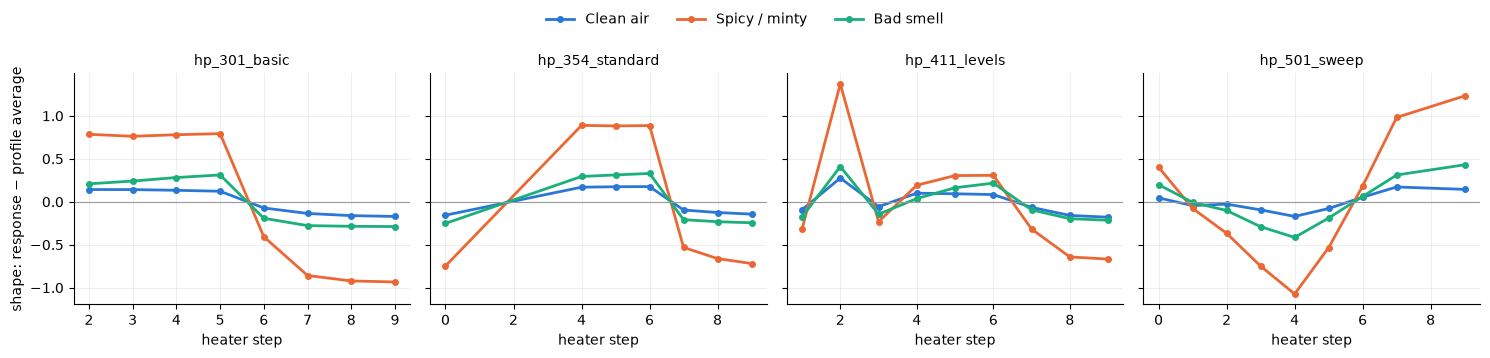

In [17]:
COLORS = {'clean_air': '#2a78d6', 'spicy': '#eb6834', 'bad_smell': '#1baf7a'}
NAMES = {'clean_air': 'Clean air', 'spicy': 'Spicy / minty', 'bad_smell': 'Bad smell'}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for ax, prof in zip(axes, PROFILES):
    cols = [f'{prof}_shape_s{i}' for i in USE_STEPS[prof]]
    for cls in CLASSES:
        d = data[data['class'] == cls]
        curve = d[cols].to_numpy()
        ax.plot(USE_STEPS[prof], np.nanmean(curve, axis=0), marker='o', ms=4, lw=2, color=COLORS[cls], label=NAMES[cls])
    ax.axhline(0, color='#999', lw=0.8)
    ax.set_title(prof, fontsize=10); ax.set_xlabel('heater step'); ax.grid(alpha=0.2)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('shape: response − profile average')
fig.legend(*axes[0].get_legend_handles_labels(), loc='upper center', ncol=3, frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.9)); plt.savefig('class_curves.png', dpi=130); plt.show()

## 5. Train and test honestly
Two tests, both at the level of whole sessions (all windows of a session are averaged into one answer):
- **unseen board**: train on two boards, test on the third;
- **unseen session**: train on all sessions except one, test on it.

Balanced accuracy counts each class equally. Guessing gives 33%.

In [18]:
def make_logreg():
    return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                         LogisticRegression(C=1.0, max_iter=5000, class_weight='balanced'))

def session_predictions(df, feats, make_model, split):
    truth, guess, probs = [], [], []
    groups = df['board'] if split == 'board' else df['session']
    for g in groups.unique():
        test = groups == g
        train = ~test
        if df.loc[train, 'class'].nunique() < len(CLASSES): continue
        model = make_model().fit(df.loc[train, feats], df.loc[train, 'class'])
        for sid, part in df[test].groupby('session'):
            p = model.predict_proba(part[feats]).mean(axis=0)
            truth.append(part['class'].iloc[0]); guess.append(model.classes_[p.argmax()]); probs.append(p.max())
    return np.array(truth), np.array(guess), np.array(probs)

results = {}
for name, maker in [('Logistic regression', make_logreg), (BOOSTING_NAME, make_boosting)]:
    for split, label in [('board', 'unseen board'), ('session', 'unseen session')]:
        t, g, p = session_predictions(data, FEATURES, maker, split)
        results[(name, label)] = (t, g, p)
        print(f'{name:34s} {label:15s} balanced accuracy {balanced_accuracy_score(t, g):.0%}  ({len(t)} sessions)')

Logistic regression                unseen board    balanced accuracy 81%  (55 sessions)
Logistic regression                unseen session  balanced accuracy 76%  (55 sessions)
Gradient boosting (scikit-learn)   unseen board    balanced accuracy 70%  (55 sessions)
Gradient boosting (scikit-learn)   unseen session  balanced accuracy 71%  (55 sessions)


In [19]:
t, g, _ = results[('Logistic regression', 'unseen board')]
cm = confusion_matrix(t, g, labels=CLASSES)
print('Unseen board, logistic regression. Rows = truth, columns = prediction')
print(pd.DataFrame(cm, index=[NAMES[c] for c in CLASSES], columns=[NAMES[c] for c in CLASSES]))

Unseen board, logistic regression. Rows = truth, columns = prediction
               Clean air  Spicy / minty  Bad smell
Clean air             11              2          1
Spicy / minty          9             19          2
Bad smell              0              0         11


## 6. Test on board 3
Board 3 runs profiles 354, 411, 501 and 502 instead of 301, 354, 411 and 501, so this test uses a model
built only from the three shared profiles. Board 3 never took part in training.
- clean air: Test_2 and Test_4
- cinnamon (spicy) at 15 cm, 30 cm, 50 cm, 1 m, 2 m and 4 m: Test_1. Cinnamon from boards 1 and 2 at the same
  distances is shown for comparison (also not used in training).

Note: board 3 used profiles 354/411/501/502 in Test_1 and Test_2 but 301/354/411/501 in Test_4, so its two
clean-air sessions cannot be checked against each other; only the cinnamon sessions can be tested.

In [20]:
SHARED_FEATURES = [c for c in FEATURES if c.split('_')[0] + '_' + c.split('_')[1] + '_' + c.split('_')[2] in SHARED]
shared_model = make_logreg().fit(data[SHARED_FEATURES], data['class'])
check = [s for s in sessions if s['board'] == TEST_BOARD or s['source'] == 'Test_1']
rows = []
for s in check:
    f = features(s, SHARED)
    if f is None or f.empty: continue
    p = shared_model.predict_proba(f[SHARED_FEATURES]).mean(axis=0)
    best = shared_model.classes_[p.argmax()]
    rows.append(dict(board=s['board'], test=s['source'], object=s['label'], truth=s['cls'],
                     prediction=best if p.max() >= UNKNOWN_BELOW else 'unknown',
                     **{f'P({NAMES[c]})': round(p[list(shared_model.classes_).index(c)], 2) for c in CLASSES}))
board3 = pd.DataFrame(rows).sort_values(['test', 'object', 'board'])
print(board3.to_string(index=False))

board   test           object truth prediction  P(Clean air)  P(Spicy / minty)  P(Bad smell)
 bme1 Test_1 Scortisoara_15cm spicy  clean_air          0.85              0.09          0.07
 bme2 Test_1 Scortisoara_15cm spicy  clean_air          0.61              0.26          0.13
 bme3 Test_1 Scortisoara_15cm spicy  clean_air          0.74              0.14          0.12
 bme1 Test_1   Scortisoara_1m spicy  clean_air          0.71              0.10          0.19
 bme2 Test_1   Scortisoara_1m spicy    unknown          0.53              0.14          0.33
 bme3 Test_1   Scortisoara_1m spicy    unknown          0.30              0.12          0.58
 bme1 Test_1   Scortisoara_2m spicy  clean_air          0.65              0.12          0.24
 bme2 Test_1   Scortisoara_2m spicy    unknown          0.54              0.11          0.35
 bme3 Test_1   Scortisoara_2m spicy  bad_smell          0.24              0.12          0.64
 bme1 Test_1 Scortisoara_30cm spicy  clean_air          0.78          

## 7. Export the model for the interface
The final model is trained on **all** sessions from boards 1, 2 and 4. The JSON has:
- `metadata`: what the Classifier page already reads (name, classes, profile requirements, timing);
- `model`: everything needed to predict on the Pi (feature list, imputation, scaling, weights);
- `clean_air_reference`: the latest ln R₀ per board, sensor and step. On the device, record fresh clean air first.

In [21]:
final = make_logreg().fit(data[FEATURES], data['class'])
imputer, scaler, logreg = final.named_steps.values()
presets = {'hp_301_basic': ([100,100,200,200,200,200,320,320,320,320], [2,41,2,14,14,14,2,14,14,14]),
           'hp_354_standard': ([320,100,100,100,200,200,200,320,320,320], [5,2,10,30,5,5,5,5,5,5]),
           'hp_411_levels': ([100,320,170,320,240,240,240,320,320,320], [43,2,43,2,2,20,21,2,20,21]),
           'hp_501_sweep': ([210,265,265,320,320,265,210,155,100,155], [24,2,22,2,22,24,24,24,24,24])}
latest_ref = {}
for board in TRAIN_BOARDS:
    refs = [r for r in calibrations if r[0] == board]
    if refs:
        b, when, _, prof = max(refs, key=lambda r: r[1])
        latest_ref[board] = {'recorded_at': when.isoformat(),
                             'ln_r0': {f'sensor{k[0]}_{k[1]}': [None if np.isnan(v) else round(float(v), 5) for v in vals]
                                       for k, vals in prof.items()}}
model_json = {
    'metadata': {
        'name': 'Clean air / spicy / bad smell', 'version': '0.2',
        'description': 'Logistic regression on the curve shape of clean-air-referenced BME688 responses. Trained on boards 1, 2, 4.',
        'classes': CLASSES,
        'window_seconds': WINDOW_S, 'warmup_seconds': SKIP_MIN * 60, 'prediction_interval_seconds': 30,
        'profile_requirements': [{'profile': p, 'count': 2, 'mode': 'parallel', 'duty': 0, 'sleep': 0,
                                  'temps': presets[p][0], 'ticks': presets[p][1]} for p in PROFILES],
    },
    'model': {
        'type': 'multinomial_logistic_regression',
        'features': FEATURES, 'use_steps': USE_STEPS, 'clip_ohm': CLIP_OHM,
        'feature_recipe': 'response = ln R0 - ln R per sensor and step; mean of the 2 sensors per profile over a '
                          f'{WINDOW_S}s window; shape = response at use_steps - mean response at use_steps',
        'impute_median': imputer.statistics_.round(6).tolist(),
        'scaler_mean': scaler.mean_.round(6).tolist(), 'scaler_scale': scaler.scale_.round(6).tolist(),
        'classes': logreg.classes_.tolist(),
        'coef': logreg.coef_.round(6).tolist(), 'intercept': logreg.intercept_.round(6).tolist(),
        'unknown_below': UNKNOWN_BELOW,
    },
    'clean_air_reference': latest_ref,
    'training': {'sessions': int(data.session.nunique()), 'examples': int(len(data)),
                 'boards': TRAIN_BOARDS,
                 'balanced_accuracy_unseen_board': round(float(balanced_accuracy_score(*results[('Logistic regression', 'unseen board')][:2])), 3),
                 'balanced_accuracy_unseen_session': round(float(balanced_accuracy_score(*results[('Logistic regression', 'unseen session')][:2])), 3)},
}
Path('smell_classifier_v0.2.json').write_text(json.dumps(model_json, indent=1, ensure_ascii=False))
print('saved smell_classifier_v0.2.json')

saved smell_classifier_v0.2.json


### Which numbers matter most?
The largest weights show what the model relies on for each class.

In [22]:
weights = pd.DataFrame(logreg.coef_, index=logreg.classes_, columns=FEATURES).T
for cls in CLASSES:
    top = weights[cls].sort_values(key=abs, ascending=False).head(5)
    print(f'{NAMES[cls]:14s}', ', '.join(f'{k} ({v:+.2f})' for k, v in top.items()))

Clean air      hp_411_levels_shape_s3 (+3.65), hp_301_basic_shape_s2 (+2.65), hp_501_sweep_shape_s2 (-2.33), hp_411_levels_shape_s4 (+2.32), hp_301_basic_shape_s3 (+2.05)
Spicy / minty  hp_301_basic_shape_s5 (+3.23), hp_411_levels_shape_s2 (+2.59), hp_301_basic_shape_s2 (-2.23), hp_411_levels_shape_s8 (-1.86), hp_411_levels_shape_s9 (-1.81)
Bad smell      hp_411_levels_shape_s8 (+2.74), hp_411_levels_shape_s6 (+2.28), hp_411_levels_shape_s3 (-2.11), hp_354_standard_shape_s0 (-1.93), hp_411_levels_shape_s2 (-1.89)


## What the results mean
- On a board it has never seen, the model is right for about **4 of 5 sessions** (balanced accuracy 80%,
  guessing gives 33%). Bad smells: 11/11, clean air: 10/13, spicy: 19/30. Spicy is most often confused with clean air.
- Using only the curve shape (no strength) was better than shape + strength (80% vs 73%): the strength carried
  most of the sensor drift. Logistic regression with C = 1–3 was the best model in every setting we tried;
  LDA, SVM and gradient boosting were 60–70%.
- **Cinnamon in the distance test (Test_1) is still not recognised**, not even at 15 cm. In open air its curve
  is much weaker than the close-up training recordings and looks like clean air to the model.
- We chose the settings after trying many, which makes the numbers somewhat optimistic.
  The real test is new recordings on board 3 with the standard profiles and clean air before every sample.